# 🛍️ Product Sentiment Analysis
## Amazon Review Polarity — EDA, Training & Model Export

**Dataset:** [CyranoB/polarity](https://huggingface.co/datasets/CyranoB/polarity)  
**Source:** Amazon reviews (18-year span, ~35M reviews), binary sentiment (negative / positive)  
**Model:** TF-IDF + Logistic Regression pipeline, serialized with `joblib`


---
## 📦 1. Imports & Setup

In [1]:
import os
import re
import warnings
import joblib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score, roc_curve
)

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

NEG_COLOR = '#EF4444'
POS_COLOR = '#10B981'
ACCENT    = '#6366F1'

print('All imports successful')

c:\Users\anil kumar.D\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports successful


---
## 📥 2. Load Dataset from HuggingFace (CyranoB/polarity)

In [2]:
TRAIN_SAMPLES = 60000
TEST_SAMPLES  = 10000
CACHE_FILE    = '../data/polarity_sample.parquet'

if os.path.exists(CACHE_FILE):
    print(f'Loading cached sample from {CACHE_FILE}...')
    df = pd.read_parquet(CACHE_FILE)
    print(f'Loaded {len(df):,} rows from cache')
else:
    print('Streaming dataset from HuggingFace (CyranoB/polarity)...')
    ds_train = load_dataset('CyranoB/polarity', split='train', streaming=True, trust_remote_code=True)
    ds_test  = load_dataset('CyranoB/polarity', split='test',  streaming=True, trust_remote_code=True)

    train_rows, test_rows = [], []
    for i, row in enumerate(ds_train):
        if i >= TRAIN_SAMPLES: break
        train_rows.append(row)
    for i, row in enumerate(ds_test):
        if i >= TEST_SAMPLES: break
        test_rows.append(row)

    df_train = pd.DataFrame(train_rows)
    df_test  = pd.DataFrame(test_rows)
    df_train['split'] = 'train'
    df_test['split']  = 'test'
    df = pd.concat([df_train, df_test], ignore_index=True)

    os.makedirs('../data', exist_ok=True)
    df.to_parquet(CACHE_FILE, index=False)
    print(f'Saved {len(df):,} rows to {CACHE_FILE}')

print(f'Dataset shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head(3)

Loading cached sample from ../data/polarity_sample.parquet...
Loaded 30,000 rows from cache
Dataset shape: (30000, 4)
Columns: ['label', 'title', 'content', 'split']


,label,title,content,split
0,1,Stuning even for the non-gamer,This sound track was beautiful! It paints the ...,train
1,1,The best soundtrack ever to anything.,I'm reading a lot of reviews saying that this ...,train
2,1,Amazing!,This soundtrack is my favorite music of all ti...,train


---
## 🔍 3. Exploratory Data Analysis (EDA)
### 3.1 Dataset Overview

In [3]:
print('Total rows    :', len(df))
print('Total columns :', df.shape[1])
print('\nMissing values:')
print(df.isnull().sum())
print('\nLabel distribution:')
print(df['label'].value_counts().rename({0:'negative', 1:'positive'}))
df.describe(include='object')

Total rows    : 30000
Total columns : 4

Missing values:
label      0
title      0
content    0
split      0
dtype: int64

Label distribution:
label
positive    15448
negative    14552
Name: count, dtype: int64


,title,content,split
count,30000,30000,30000
unique,27009,29982,2
top,Disappointed,Very bad Keanu Reeves film that could be one o...,train
freq,79,3,25000


### 3.2 Class Distribution

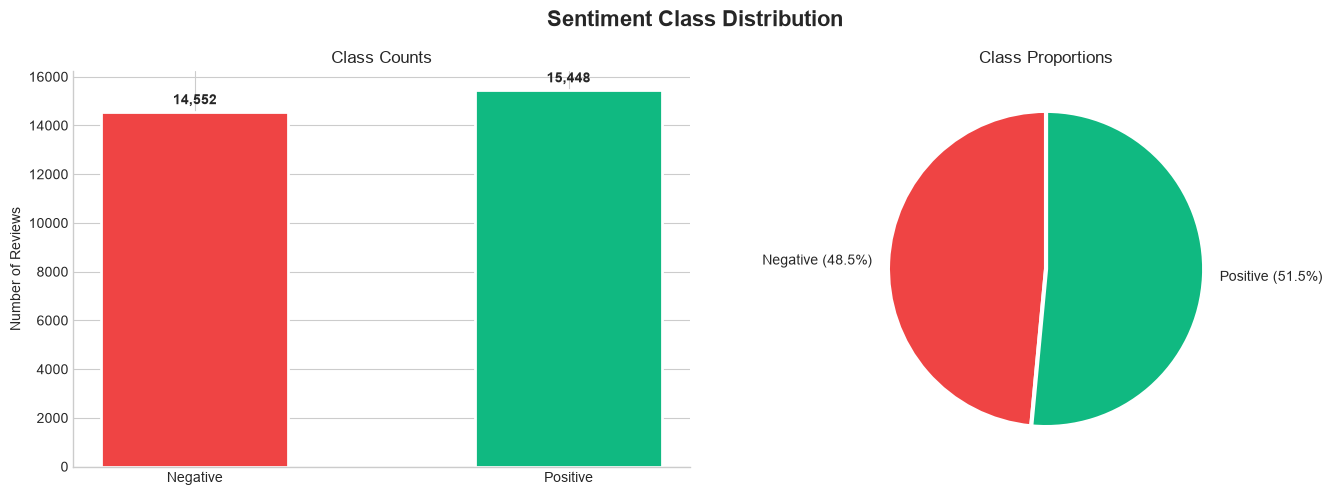

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Sentiment Class Distribution', fontsize=16, fontweight='bold')

label_counts = df['label'].value_counts().sort_index()
bars = axes[0].bar(['Negative', 'Positive'], label_counts.values,
                   color=[NEG_COLOR, POS_COLOR], edgecolor='white', linewidth=2, width=0.5)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 200,
                 f'{bar.get_height():,}', ha='center', va='bottom', fontweight='bold')
axes[0].set_title('Class Counts'); axes[0].set_ylabel('Number of Reviews')
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

pct = label_counts.values / label_counts.values.sum() * 100
axes[1].pie(label_counts.values,
            labels=[f'Negative ({pct[0]:.1f}%)', f'Positive ({pct[1]:.1f}%)'],
            colors=[NEG_COLOR, POS_COLOR], startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':3})
axes[1].set_title('Class Proportions')

plt.tight_layout()
os.makedirs('../data', exist_ok=True)
plt.savefig('../data/eda_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.3 Text Length Analysis

Content word count stats:
            count  mean   std   min   25%   50%    75%    max
label                                                        
negative  14552.0  77.9  42.4   7.0  43.0  70.0  108.0  206.0
positive  15448.0  72.4  42.9  10.0  36.0  62.0  101.0  206.0


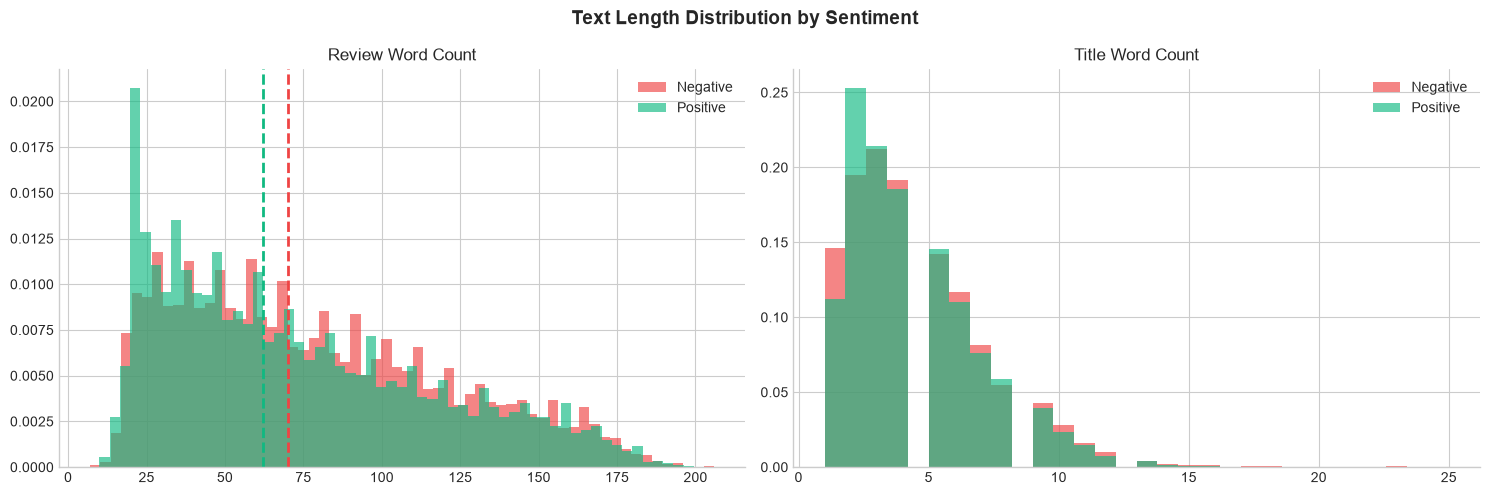

In [5]:
df['content_words'] = df['content'].fillna('').str.split().str.len()
df['title_words']   = df['title'].fillna('').str.split().str.len()

print('Content word count stats:')
print(df.groupby('label')['content_words'].describe().round(1).rename(index={0:'negative', 1:'positive'}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Text Length Distribution by Sentiment', fontsize=14, fontweight='bold')

neg = df[df['label']==0]['content_words']
pos = df[df['label']==1]['content_words']

axes[0].hist(neg.clip(0,300), bins=60, alpha=0.65, color=NEG_COLOR, label='Negative', density=True)
axes[0].hist(pos.clip(0,300), bins=60, alpha=0.65, color=POS_COLOR, label='Positive', density=True)
axes[0].axvline(neg.median(), color=NEG_COLOR, linestyle='--', lw=2)
axes[0].axvline(pos.median(), color=POS_COLOR, linestyle='--', lw=2)
axes[0].set_title('Review Word Count'); axes[0].legend()

axes[1].hist(df[df['label']==0]['title_words'].clip(0,30), bins=30, alpha=0.65, color=NEG_COLOR, label='Negative', density=True)
axes[1].hist(df[df['label']==1]['title_words'].clip(0,30), bins=30, alpha=0.65, color=POS_COLOR, label='Positive', density=True)
axes[1].set_title('Title Word Count'); axes[1].legend()

for ax in axes:
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../data/eda_text_length.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.4 Top Keywords per Sentiment

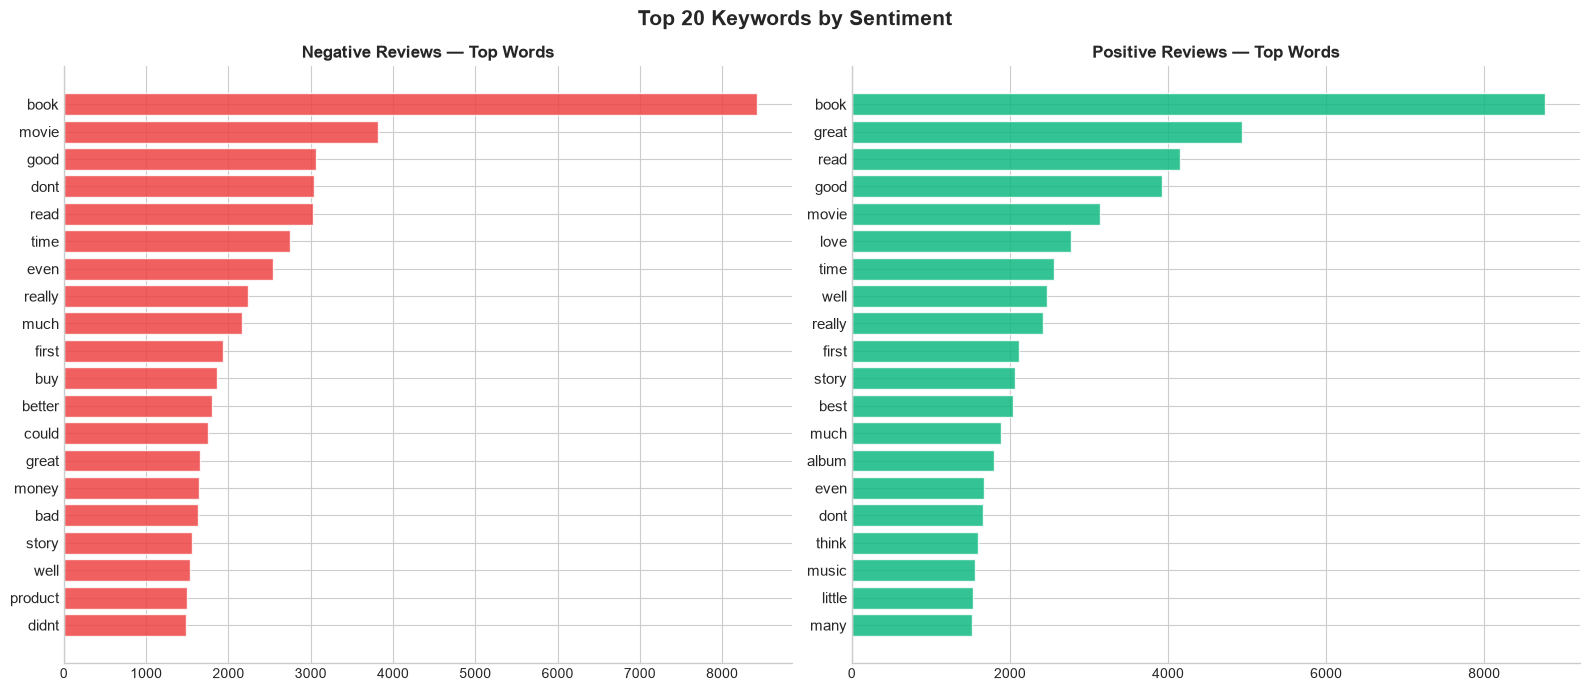

In [6]:
STOPWORDS = set(stopwords.words('english'))
STOPWORDS.update({'br','would','one','also','get','got','use','used','using','like','make','made'})

def get_top_words(texts, n=20):
    words = []
    for t in texts:
        if not isinstance(t, str): continue
        words.extend([w for w in re.sub(r'[^a-z ]', '', t.lower()).split()
                       if w not in STOPWORDS and len(w) > 2])
    return Counter(words).most_common(n)

neg_words = get_top_words(df[df['label']==0]['content'])
pos_words = get_top_words(df[df['label']==1]['content'])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Top 20 Keywords by Sentiment', fontsize=15, fontweight='bold')

def plot_top_words(ax, wcs, color, title):
    words, counts = zip(*wcs)
    y = range(len(words))
    ax.barh(y, counts, color=color, alpha=0.85, edgecolor='white')
    ax.set_yticks(y); ax.set_yticklabels(words, fontsize=11)
    ax.invert_yaxis(); ax.set_title(title, fontweight='bold')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plot_top_words(axes[0], neg_words, NEG_COLOR, 'Negative Reviews — Top Words')
plot_top_words(axes[1], pos_words, POS_COLOR, 'Positive Reviews — Top Words')

plt.tight_layout()
plt.savefig('../data/eda_top_keywords.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.5 Sample Reviews

In [7]:
print('NEGATIVE REVIEWS:')
for _, row in df[df['label']==0][['title','content']].sample(3, random_state=42).iterrows():
    print(f'  [{row["title"]}]: {str(row["content"])[:250]}')
    print()

print('\nPOSITIVE REVIEWS:')
for _, row in df[df['label']==1][['title','content']].sample(3, random_state=42).iterrows():
    print(f'  [{row["title"]}]: {str(row["content"])[:250]}')
    print()

NEGATIVE REVIEWS:
  [wow, what a mess]: If you read the Beats and about the Beats, you're eventually going to come to William S. Burroughs. He's very much a voice of the 1950s, post World War II. He was into the drugs, longer and harder and deeper than anyone else. He was into shocking the

  [Sacreligious]: I agree with the "disappointing" review and would add that the resolution of the mystery could have and should have been without the author's own agenda. To suggest that the Blessed Mother would actually call for murder, suicide, abortion, homosexual

  [Five-star movie, one-star "Special Edition" DVD]: Commercials on DVDs are nothing new. Annoying though they are, you can always skip them with a click of the remote, right? Not anymore. For Babe, a title targeted at kids no less, Universal saw fit to make the commercials non-skippable. They start as


POSITIVE REVIEWS:
  [Wonderfully romantic book that sweeps you to Italy]: THE FOOD OF LOVE is absolutely amazing. From page one I fe

---
## 🛠️ 4. Text Preprocessing

In [8]:
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens
              if w not in STOPWORDS and len(w) > 2]
    return ' '.join(tokens)

print('Preprocessing text (title + content)...')
df['text'] = df['title'].fillna('') + ' ' + df['content'].fillna('')
df['text_clean'] = df['text'].apply(preprocess)

print('Done!')
print('\nSample raw    :', df['text'].iloc[0][:200])
print('\nSample cleaned:', df['text_clean'].iloc[0][:200])

Preprocessing text (title + content)...
Done!

Sample raw    : Stuning even for the non-gamer This sound track was beautiful! It paints the senery in your mind so well I would recomend it even to people who hate vid. game music! I have played the game Chrono Cros

Sample cleaned: stuning even non gamer sound track beautiful paint senery mind well recomend even people hate vid game music played game chrono cross game ever played best music back away crude keyboarding take fresh


---
## ✂️ 5. Train/Validation/Test Split

In [9]:
df_train = df[df['split'] == 'train'].copy()
df_test  = df[df['split'] == 'test'].copy()

X_train, X_val, y_train, y_val = train_test_split(
    df_train['text_clean'], df_train['label'],
    test_size=0.15, random_state=42, stratify=df_train['label']
)
X_test = df_test['text_clean']
y_test  = df_test['label']

print(f'Training set   : {len(X_train):,}')
print(f'Validation set : {len(X_val):,}')
print(f'Test set       : {len(X_test):,}')

Training set   : 21,250
Validation set : 3,750
Test set       : 5,000


---
## 🤖 6. Model Training — TF-IDF + Logistic Regression

In [10]:
import time

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=80000,
        ngram_range=(1, 2),
        min_df=3,
        max_df=0.90,
        sublinear_tf=True,
    )),
    ('clf', LogisticRegression(
        C=5.0, max_iter=1000, solver='saga',
        n_jobs=-1, random_state=42
    ))
])

print('Training TF-IDF + Logistic Regression pipeline...')
t0 = time.time()
pipeline.fit(X_train, y_train)
print(f'Training completed in {time.time()-t0:.1f}s')

Training TF-IDF + Logistic Regression pipeline...
Training completed in 2.9s


---
## 📊 7. Model Evaluation

In [11]:
for name, X, y in [('Validation', X_val, y_val), ('Test', X_test, y_test)]:
    y_pred = pipeline.predict(X)
    y_prob = pipeline.predict_proba(X)[:,1]
    acc = accuracy_score(y, y_pred)
    auc = roc_auc_score(y, y_prob)
    print(f'--- {name} Set ---')
    print(f'Accuracy: {acc:.4f} | ROC-AUC: {auc:.4f}\n')
    print(classification_report(y, y_pred, target_names=['Negative','Positive']))

--- Validation Set ---
Accuracy: 0.8744 | ROC-AUC: 0.9470

              precision    recall  f1-score   support

    Negative       0.88      0.86      0.87      1818
    Positive       0.87      0.89      0.88      1932

    accuracy                           0.87      3750
   macro avg       0.87      0.87      0.87      3750
weighted avg       0.87      0.87      0.87      3750

--- Test Set ---
Accuracy: 0.8694 | ROC-AUC: 0.9451

              precision    recall  f1-score   support

    Negative       0.88      0.84      0.86      2435
    Positive       0.86      0.89      0.88      2565

    accuracy                           0.87      5000
   macro avg       0.87      0.87      0.87      5000
weighted avg       0.87      0.87      0.87      5000



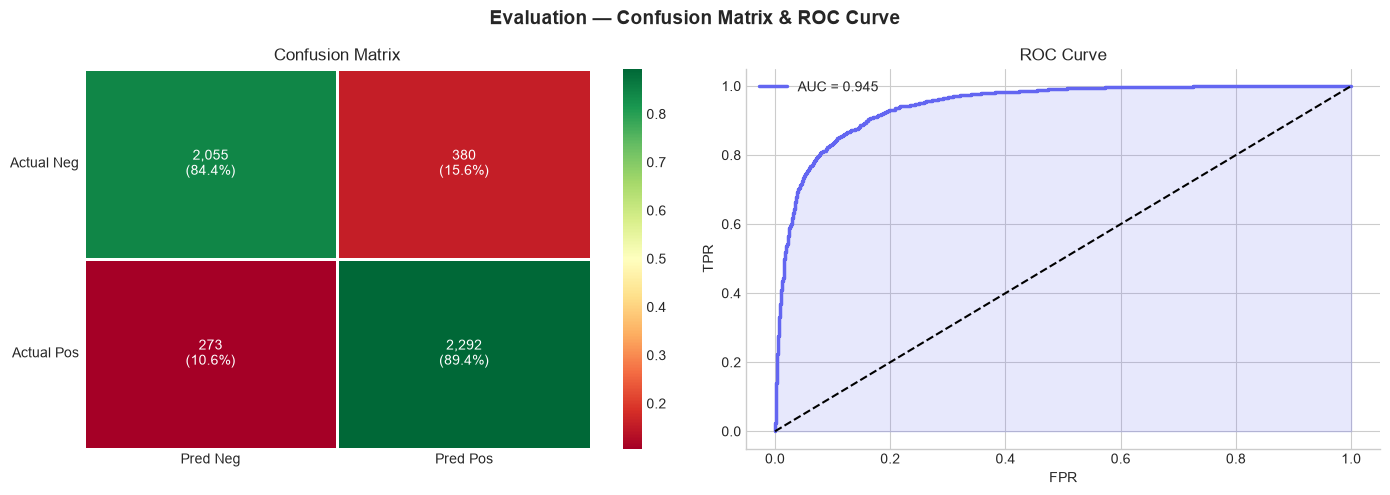

In [12]:
y_pred_test = pipeline.predict(X_test)
y_prob_test = pipeline.predict_proba(X_test)[:,1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Evaluation — Confusion Matrix & ROC Curve', fontsize=14, fontweight='bold')

cm = confusion_matrix(y_test, y_pred_test)
cm_pct = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
annot = np.array([[f'{cm[i,j]:,}\n({cm_pct[i,j]*100:.1f}%)' for j in range(2)] for i in range(2)])
sns.heatmap(cm_pct, annot=annot, fmt='', cmap='RdYlGn', ax=axes[0],
            xticklabels=['Pred Neg','Pred Pos'], yticklabels=['Actual Neg','Actual Pos'],
            linewidths=2, linecolor='white')
axes[0].set_title('Confusion Matrix'); axes[0].tick_params(axis='y', rotation=0)

fpr, tpr, _ = roc_curve(y_test, y_prob_test)
auc_score = roc_auc_score(y_test, y_prob_test)
axes[1].plot(fpr, tpr, color=ACCENT, lw=2.5, label=f'AUC = {auc_score:.3f}')
axes[1].plot([0,1],[0,1],'k--',lw=1.5)
axes[1].fill_between(fpr, tpr, alpha=0.15, color=ACCENT)
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve'); axes[1].legend()
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../data/eval_confusion_roc.png', dpi=150, bbox_inches='tight')
plt.show()

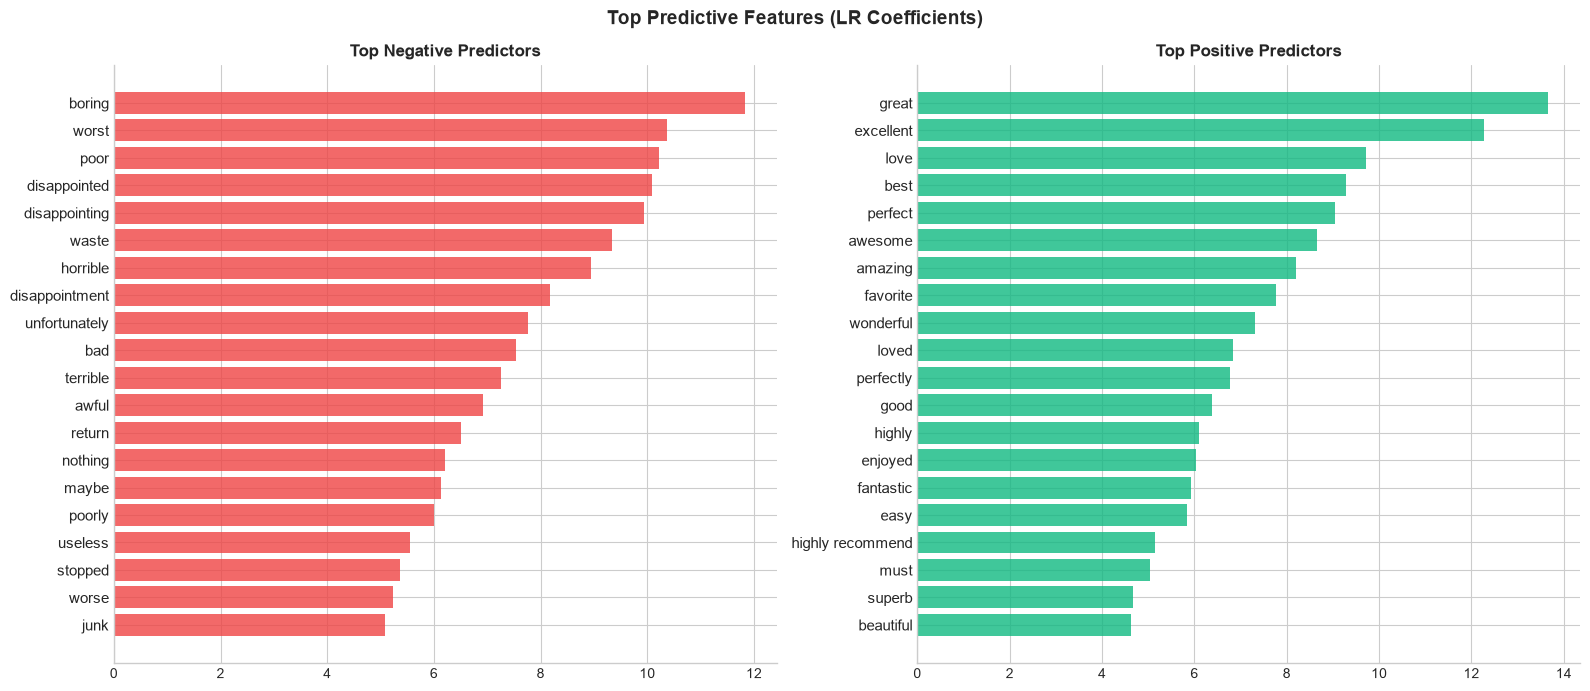

In [13]:
feat_names = pipeline.named_steps['tfidf'].get_feature_names_out()
coefs      = pipeline.named_steps['clf'].coef_[0]

top_neg = np.argsort(coefs)[:20]
top_pos = np.argsort(coefs)[-20:][::-1]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Top Predictive Features (LR Coefficients)', fontsize=14, fontweight='bold')

def plot_feats(ax, idx, color, title):
    words = [feat_names[i] for i in idx]
    vals  = [abs(coefs[i]) for i in idx]
    ax.barh(range(len(words)), vals, color=color, alpha=0.8)
    ax.set_yticks(range(len(words))); ax.set_yticklabels(words, fontsize=11)
    ax.invert_yaxis(); ax.set_title(title, fontweight='bold')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plot_feats(axes[0], top_neg, NEG_COLOR, 'Top Negative Predictors')
plot_feats(axes[1], top_pos, POS_COLOR, 'Top Positive Predictors')
plt.tight_layout()
plt.savefig('../data/eval_top_features.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 💾 8. Save (Freeze) the Model

In [14]:
MODEL_DIR = '../backend/models'
os.makedirs(MODEL_DIR, exist_ok=True)

pipeline_path = os.path.join(MODEL_DIR, 'sentiment_pipeline.joblib')
joblib.dump(pipeline, pipeline_path, compress=3)

test_acc = accuracy_score(y_test, pipeline.predict(X_test))
test_auc = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:,1])

metadata = {
    'model_type': 'TF-IDF + Logistic Regression Pipeline',
    'dataset': 'CyranoB/polarity (Amazon Review Polarity)',
    'train_samples': int(len(X_train)),
    'test_samples': int(len(X_test)),
    'tfidf_max_features': 80000,
    'ngram_range': '(1,2)',
    'test_accuracy': round(test_acc, 4),
    'test_roc_auc': round(test_auc, 4),
    'classes': {'0': 'negative', '1': 'positive'}
}

with open(os.path.join(MODEL_DIR, 'model_metadata.json'), 'w') as f:
    json.dump(metadata, f, indent=2)

print(f'Model saved: {pipeline_path}')
for k, v in metadata.items():
    print(f'  {k}: {v}')

Model saved: ../backend/models\sentiment_pipeline.joblib
  model_type: TF-IDF + Logistic Regression Pipeline
  dataset: CyranoB/polarity (Amazon Review Polarity)
  train_samples: 21250
  test_samples: 5000
  tfidf_max_features: 80000
  ngram_range: (1,2)
  test_accuracy: 0.8694
  test_roc_auc: 0.9451
  classes: {'0': 'negative', '1': 'positive'}


---
## 🧪 9. Frozen Model Inference Test

In [15]:
test_reviews = [
    "This product is absolutely amazing! Best purchase I've ever made. Highly recommend!",
    "Terrible quality. Broke after two days. Complete waste of money. Very disappointed.",
    "It's okay. Does what it says, nothing special. Average product for the price.",
    "Exceeded my expectations! Works perfectly and arrived quickly. 5 stars!",
    "Don't buy this. The instructions are confusing and quality is awful."
]

loaded = joblib.load(pipeline_path)

print('Inference on test reviews (frozen model):')
print('='*65)
for review in test_reviews:
    cleaned = preprocess(review)
    pred  = loaded.predict([cleaned])[0]
    proba = loaded.predict_proba([cleaned])[0]
    label = 'POSITIVE' if pred == 1 else 'NEGATIVE'
    print(f'Review: {review[:70]}')
    print(f'  -> {label} (neg={proba[0]:.3f}, pos={proba[1]:.3f})')
    print()

print('Frozen model inference verified!')

Inference on test reviews (frozen model):
Review: This product is absolutely amazing! Best purchase I've ever made. High
  -> POSITIVE (neg=0.005, pos=0.995)

Review: Terrible quality. Broke after two days. Complete waste of money. Very 
  -> NEGATIVE (neg=1.000, pos=0.000)

Review: It's okay. Does what it says, nothing special. Average product for the
  -> NEGATIVE (neg=0.955, pos=0.045)

Review: Exceeded my expectations! Works perfectly and arrived quickly. 5 stars
  -> POSITIVE (neg=0.036, pos=0.964)

Review: Don't buy this. The instructions are confusing and quality is awful.
  -> NEGATIVE (neg=0.998, pos=0.002)

Frozen model inference verified!
